In [1]:
import requests
import json
import matplotlib.pyplot as plt

In [4]:
# 동영상 ID
video_id = "92GOCxay1tA"

get url!!!
get url finished!!!!!


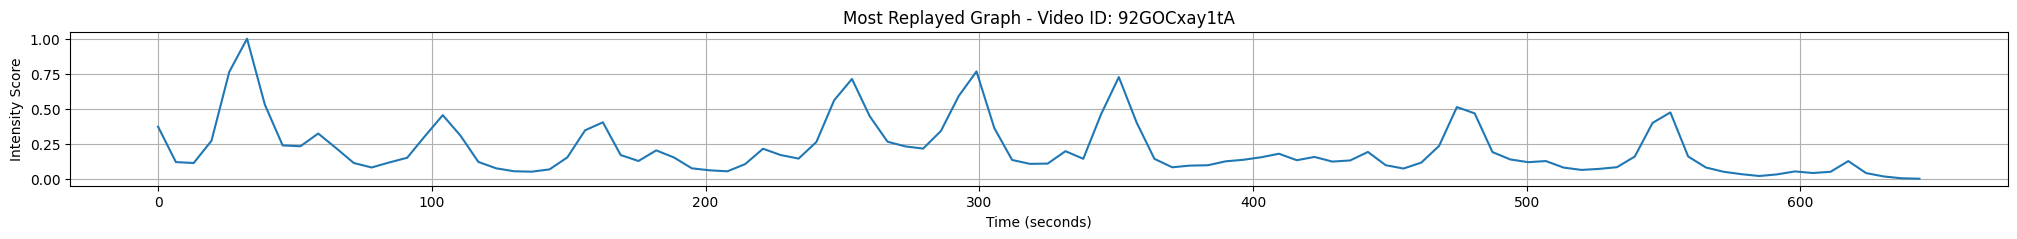

In [5]:



# API 엔드포인트 URL
url = f"https://yt.lemnoslife.com/videos?part=mostReplayed&id={video_id}"

# API 호출하여 JSON 데이터 가져오기
print('get url!!!')
response = requests.get(url)
print('get url finished!!!!!')
data = response.json()

# markers 리스트에서 startMillis와 intensityScoreNormalized 값 추출
markers = data['items'][0]['mostReplayed']['markers']
start_millis = [marker['startMillis'] for marker in markers]
intensity_scores = [marker['intensityScoreNormalized'] for marker in markers]

# 밀리초를 초로 변환
start_seconds = [millis / 1000 for millis in start_millis]

# 그래프 그리기
plt.figure(figsize=(25, 2))
plt.plot(start_seconds, intensity_scores)
plt.title(f'Most Replayed Graph - Video ID: {video_id}')
plt.xlabel('Time (seconds)')
plt.ylabel('Intensity Score')
plt.grid(True)
plt.show()


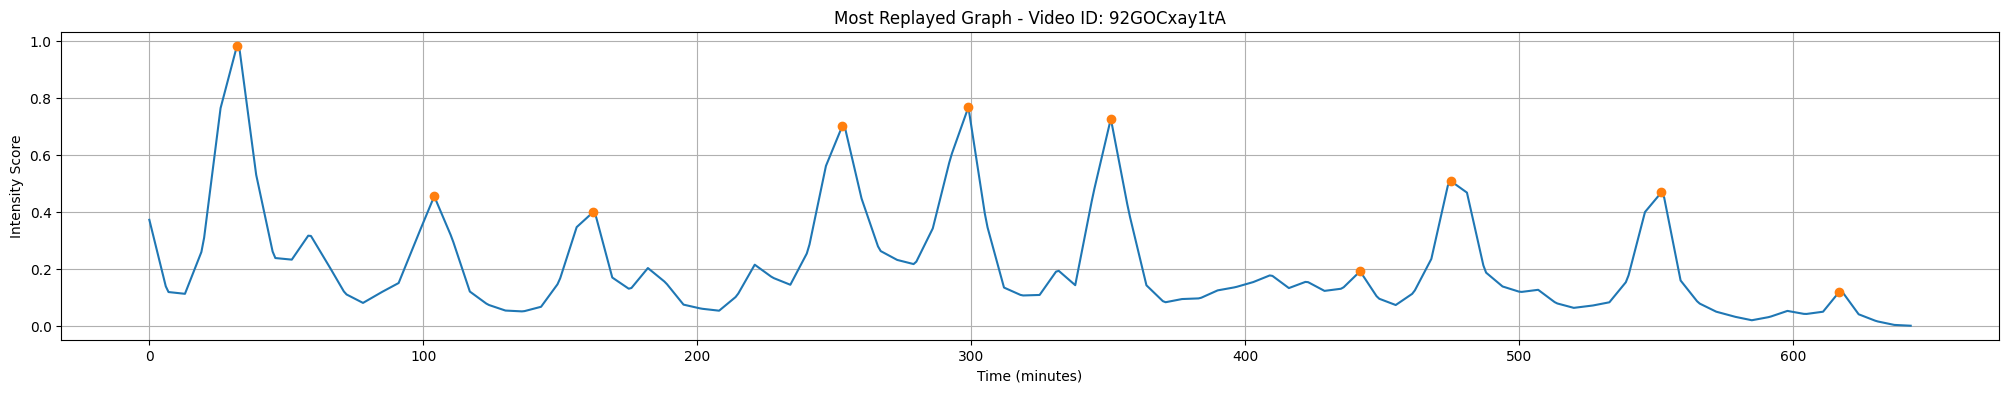

In [6]:
# 보간 함수 생성
from scipy.interpolate import interp1d
import numpy as np
from scipy.signal import find_peaks

interpolation_function = interp1d(start_seconds, intensity_scores, kind='linear', fill_value="extrapolate")

# 1초 간격으로 새로운 시간 생성
total_duration_seconds = start_seconds[-1]
new_time = np.arange(0, total_duration_seconds, 1)

# 새로운 시간에 대한 보간된 값 계산
smoothed_intensity_scores = interpolation_function(new_time)
peaks, _ = find_peaks(smoothed_intensity_scores, prominence = 0.1)

# 그래프 그리기
plt.figure(figsize=(25, 4))
plt.plot(new_time, smoothed_intensity_scores)  # 분으로 변환하여 표시
plt.plot(new_time[peaks], smoothed_intensity_scores[peaks], "o", label='Peaks')

plt.title(f'Most Replayed Graph - Video ID: {video_id}')
plt.xlabel('Time (minutes)')
plt.ylabel('Intensity Score')
plt.grid(True)
plt.show()

In [7]:
peaks

array([ 32, 104, 162, 253, 299, 351, 442, 475, 552, 617])

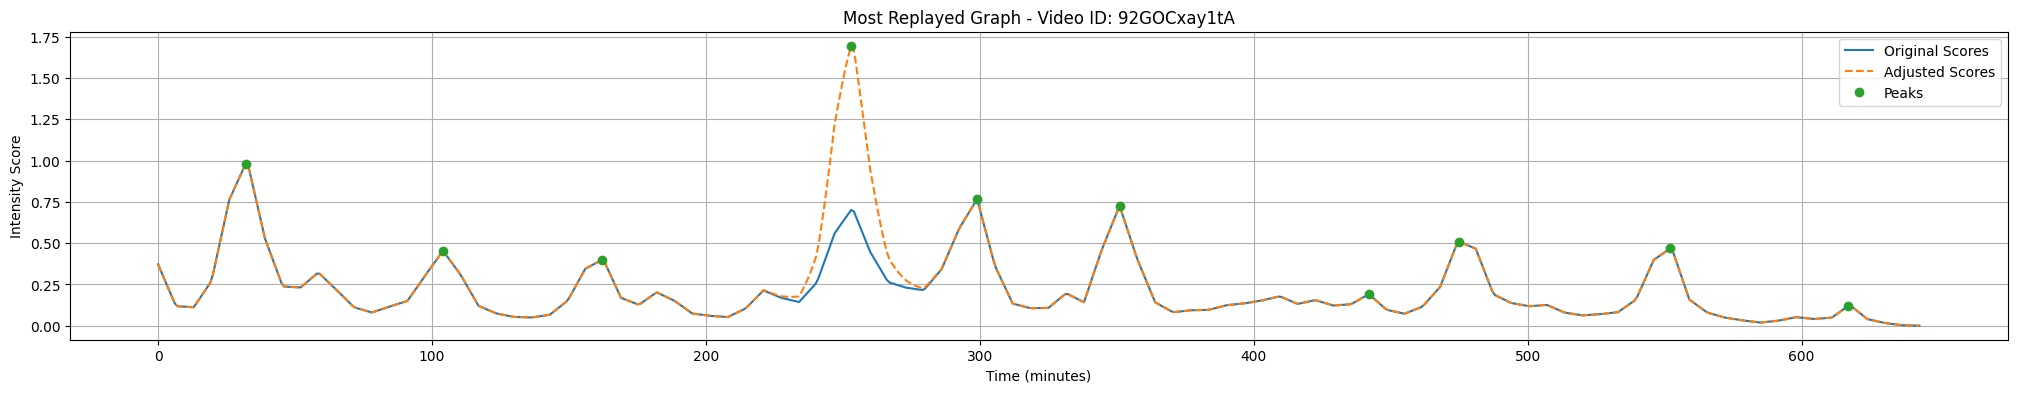

In [13]:
# 특정 점 선택
selected_point = 253  # 예시로 100번째 점 선택
sigma = 10  # 가우시안 분포의 표준편차

# 가우시안 분포 생성
# 가장 높은 피크 찾기

max_peak_value = max(smoothed_intensity_scores)

C = max_peak_value/smoothed_intensity_scores[selected_point + 1]
# 가우시안 분포 생성 (최댓값이 가장 높은 피크보다 높게 설정)
gaussian = np.exp(-((new_time - selected_point) ** 2) / (2 * sigma ** 2))

# 높이를 높게 설정
height_multiplier = 2  # 높이를 조정하는 배수
gaussian = gaussian / gaussian.max() * C
# 중요도 조정을 위해 가우시안 분포 곱하기

# gaussian = -gaussian

adjusted_scores = smoothed_intensity_scores * (1 + gaussian)

# 그래프 그리기
plt.figure(figsize=(25, 4))
plt.plot(new_time, smoothed_intensity_scores, label='Original Scores')
plt.plot(new_time, adjusted_scores, label='Adjusted Scores', linestyle='--')
plt.plot(new_time[peaks], adjusted_scores[peaks], "o", label='Peaks')

plt.title(f'Most Replayed Graph - Video ID: {video_id}')
plt.xlabel('Time (minutes)')
plt.ylabel('Intensity Score')
plt.grid(True)
plt.legend()
plt.show()

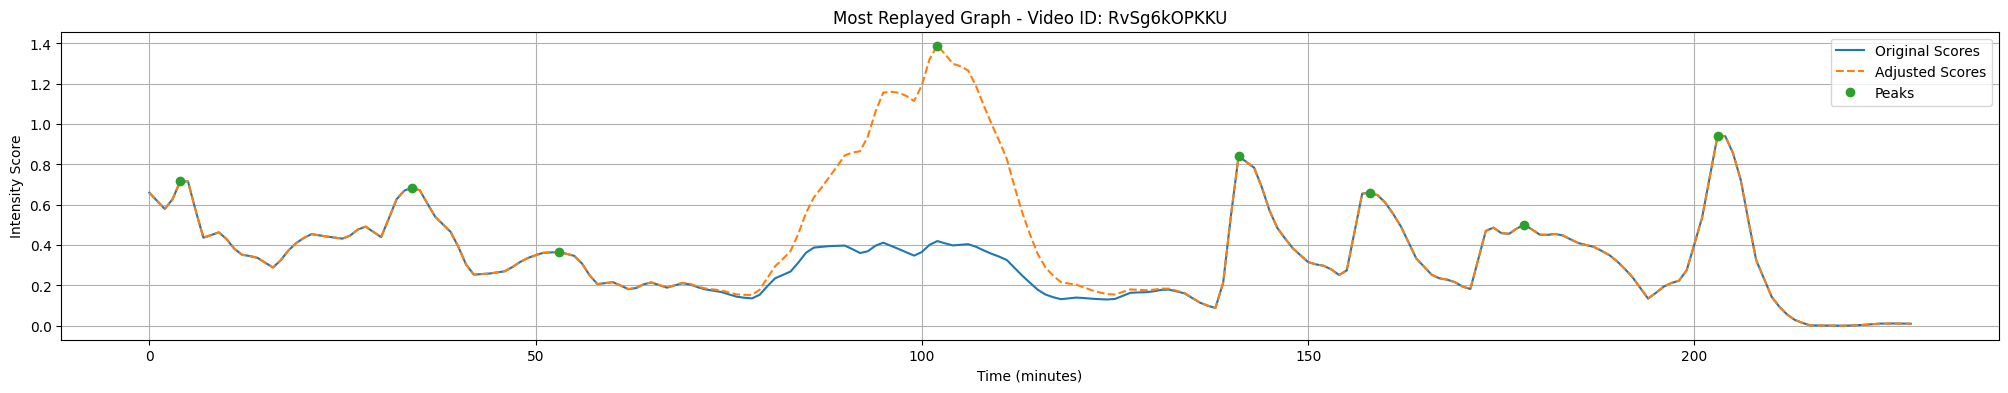

In [7]:
# # 특정 점 선택
# selected_point = 102  # 예시로 100번째 점 선택
# sigma = 10  # 가우시안 분포의 표준편차

# # 가우시안 분포 생성
# # 가장 높은 피크 찾기

# max_peak_value = max(smoothed_intensity_scores)

# C = max_peak_value/smoothed_intensity_scores[selected_point + 1]
# # 가우시안 분포 생성 (최댓값이 가장 높은 피크보다 높게 설정)
# gaussian = np.exp(-((new_time - selected_point) ** 2) / (2 * sigma ** 2))

# # 높이를 높게 설정
# height_multiplier = 2  # 높이를 조정하는 배수
# gaussian = gaussian / gaussian.max() * C
# # 중요도 조정을 위해 가우시안 분포 곱하기
# adjusted_scores = smoothed_intensity_scores * (1 + gaussian)

# # 그래프 그리기
# plt.figure(figsize=(25, 4))
# plt.plot(new_time, smoothed_intensity_scores, label='Original Scores')
# plt.plot(new_time, adjusted_scores, label='Adjusted Scores', linestyle='--')
# plt.plot(new_time[peaks], adjusted_scores[peaks], "o", label='Peaks')

# plt.title(f'Most Replayed Graph - Video ID: {video_id}')
# plt.xlabel('Time (minutes)')
# plt.ylabel('Intensity Score')
# plt.grid(True)
# plt.legend()
# plt.show()

In [10]:
# scores = smoothed_intensity_scores
scores = adjusted_scores


In [11]:
class State:
    def __init__(self, time, count, score):
        self.time = time
        self.count = count
        self.score = score
        self.frame = 0
        self.next_states = [] # 접근할 수 있는 인덱스 저장

    def get_info(self):
        # info = f'Peak: {self.peak}, Frame: {self.frame}, Count: {self.count}, Reward: {self.reward}, Time: {self.time}, Next State {self.next_states}'
        info = f'time: {self.time}, Count: {self.count},  Next State {self.next_states}'
        print(info)




In [21]:
total_time = 50

In [22]:
max_t = total_time

In [23]:
states = [[State(time=i, count=j, score=scores[i]) for j in range(max_t + 1)] for i in range(len(scores))]


In [24]:
len(states)

229

In [25]:
min_time = 2

In [26]:
# 상태들의 next_states를 설정하는 함수
def set_next_states(states, min_time, max_t):
    n = len(states)
    for i in range(n):
        for t in range(max_t + 1):
            if i + 1 < n and t + 1 <= max_t :
                states[i][t].next_states.append((i + 1, t + 1))  # 다음 시간과 새로운 t 값
            if t >= min_time:
                for j in range(i + 2, n):
                    states[i][t].next_states.append((j, 0))  # 다음 상태의 인덱스와 새로운 t 값 0


In [27]:
set_next_states(states, min_time, max_t)

In [28]:
states[0][0].next_states

[(1, 1)]

In [29]:
import numpy as np

def select_optimal_points(states, num_points=3):
    n = len(states)
    max_t = num_points
    
    # DP 테이블과 추적 테이블 초기화
    dp = np.full((n, max_t + 1, num_points + 1), -np.inf)
    dp[:, 0, 0] = 0
    trace = np.full((n, max_t + 1, num_points + 1, 2), -1, dtype=int)  # 추적 테이블 수정

    # DP 테이블 채우기
    for i in range(n):
        for t in range(max_t + 1):
            for k in range(1, num_points + 1):
                # **수정된 부분: 유효한 상태인지 확인**
                if dp[i, t, k - 1] != -np.inf:  # 유효한 상태인 경우에만 업데이트
                    for next_i, next_t in states[i][t].next_states:
                        if next_i < n and next_t <= max_t:
                            new_score = dp[i, t, k - 1] + states[next_i][next_t].score
                            if new_score > dp[next_i, next_t, k]:
                                dp[next_i, next_t, k] = new_score
                                trace[next_i, next_t, k] = (i, t)

    # 최대 점수와 마지막 인덱스 찾기
    max_score = -np.inf
    max_index = (-1, -1, -1)
    for i in range(n):
        for t in range(max_t + 1):
            if dp[i, t, num_points] > max_score:
                max_score = dp[i, t, num_points]
                max_index = (i, t, num_points)

    # 경로 추적하여 선택된 점 찾기
    selected_points = []
    k = num_points
    while max_index != (-1, -1, -1) and k > 0:
        max_index = tuple(trace[max_index[0], max_index[1], k])
        selected_points.append(max_index[0])
        k -= 1
    
    selected_points.reverse()
    return selected_points, max_score

In [71]:
def DP(states, num_points=30):
    n = len(states)
    max_t = num_points
    
    # DP 테이블과 추적 테이블 초기화
    dp = np.full((n, max_t + 1, num_points + 1), -np.inf)
    dp[:, 0, 0] = 0
    trace = np.full((n, max_t + 1, num_points + 1, 4), -1, dtype=int)

    # DP 테이블 채우기
    for i in range(n):
        for t in range(max_t + 1):
            for k in range(1, num_points + 1):
                if dp[i, t, k - 1] != -np.inf:
                    for next_i, next_t in states[i][t].next_states:
                        # if i == 162 and t == 7 and k == num_points:
                        #     pdb.set_trace()  
                        if next_i < n and next_t <= max_t:
                            new_score = dp[i, t, k - 1] + states[next_i][next_t].score
                            if new_score > dp[next_i, next_t, k]:
                                dp[next_i, next_t, k] = new_score
                                trace[next_i, next_t, k] = (i, t, next_i, next_t)

    return dp, trace


In [88]:
def find_path(states, dp, trace, num_points=30):
    n = len(states)
    max_t = num_points

    def find_max_score(exclude_index=None):
        max_score = -np.inf
        max_index = (-1, -1, -1)
        for i in range(n):
            for t in range(max_t + 1):
                if i != exclude_index and dp[i, t, num_points] > max_score:
                    max_score = dp[i, t, num_points]
                    max_index = (i, t, num_points)
        return max_score, max_index

    max_score, max_index = find_max_score()

    # 경로 추적하여 선택된 점 찾기
    selected_points = []
    k = num_points
    while max_index != (-1, -1, -1) and k > 0:
        prev_index = tuple(trace[max_index[0], max_index[1], k])
        if k == num_points - 1 :
            print(k)
            print(max_index)
            print("search next path!!!!")
            # # 마지막 점이 딸랑 1개 남는 경우, 다음 최적 경로 찾기
            # _, new_max_index = find_max_score(exclude_index=max_index[0])
            # max_index = new_max_index
            # k = num_points  # k를 리셋하여 새로운 경로에서 시작
            # selected_points = []  # 선택된 점들을 리셋
            # continue
        
        selected_points.append(max_index[0])
        max_index = prev_index
        k -= 1
    
    selected_points.reverse()

    return selected_points, max_score

In [90]:
dp, trace = DP(states, num_points=total_time) 
selected_points, max_score = find_path(states, dp, trace, num_points=total_time)


49
(177, 0, 178, 1)
search next path!!!!


In [91]:
max_score

27.302916567859683

In [92]:
def group_consecutive_points(points):
    grouped_points = []
    group = [points[0]]
    for i in range(1, len(points)):
        if points[i] == points[i-1] + 1:
            group.append(points[i])
        else:
            grouped_points.append(group)
            group = [points[i]]
    grouped_points.append(group)
    return grouped_points

In [93]:

selected_smoothed_scores = [smoothed_intensity_scores[i] for i in selected_points]

In [94]:
grouped_points = group_consecutive_points(selected_points)
group_sizes = [len(group) for group in grouped_points]

In [95]:
for group in grouped_points:
    group.append(group[-1]+1)

C:\Users\vml_sub\AppData\Local\Temp\ipykernel_275352\2105663169.py:21: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


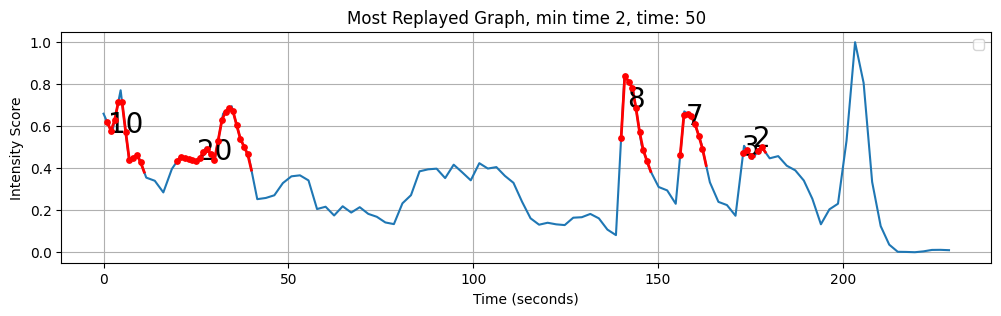

In [96]:
# 그래프 그리기
# 그래프 그리기
plt.figure(figsize=(12, 3))
plt.plot(start_seconds, intensity_scores)
plt.scatter(selected_points, selected_smoothed_scores, color='r',  s=15, zorder=5)

# 연속된 점들의 그룹 크기를 그래프에 표시
for group, size in zip(grouped_points, group_sizes):
    mid_point = group[len(group) // 2]
    plt.text(mid_point, smoothed_intensity_scores[mid_point], str(size), color='black', fontsize=20, ha='center')

for group in grouped_points:
    for i in range(len(group) -1 ):
        plt.plot([group[i], group[i + 1]], [smoothed_intensity_scores[group[i]], smoothed_intensity_scores[group[i + 1]]], color='r', linewidth=2)


plt.title(f'Most Replayed Graph, min time {min_time}, time: {total_time}')
plt.xlabel('Time (seconds)')
plt.ylabel('Intensity Score')
plt.grid(True)
plt.legend()
plt.show()